# Módulo 3 — ¿El sentimiento de noticias (FinBERT) predice la volatilidad?

**Súper test de ablation + expansión multi-sector.**

Este notebook documenta la pregunta central del proyecto: *¿combinar FinBERT con
precio aporta valor real para predecir volatilidad?* Se responde con un test
riguroso (validación temporal, walk-forward) primero en **energía** (WTI, Brent,
Henry Hub) y luego expandido a **tech, biotech y financials** para ver si el
resultado es específico de un sector o general.

## Veredicto (arriba de todo, sin vueltas)

> **FinBERT NO aporta valor robusto para predecir volatilidad — en ningún sector testeado.**
> La volatilidad la domina su propia **persistencia**; lo poco que las noticias
> aportan vive en el **volumen de cobertura**, no en el sentimiento fino. A
> frecuencia diaria, en mercados líquidos, la noticia es *contemporánea* al precio,
> no lo anticipa. Inesperadamente, **tech** (más hype) es donde menos aporta y
> **financials** el que más.

Implicación de producto: **sacar FinBERT del pipeline de volatilidad**; si se usan
noticias, usar volumen como feature de atención/régimen.

## Metodología

- **Disciplina Point-in-Time (PiT):** la feature del día `t` predice el target de
  `t+1`. Nunca se usa info del mismo día ni futura. Sin normalización global.
- **Ablation incremental:** `M0 precio` → `M1 +volumen` → `M2 +sentimiento EODHD`
  → `M3 +FinBERT`. Cada bloque se agrega sobre el anterior; el ΔAUC/ΔR² mide su aporte.
- **Dos framings del target:**
  - *Nivel de volatilidad* (realized-vol de t+1) — donde la **persistencia** es baseline.
  - *Saltos* (|retorno de t+1| en el decil superior, umbral por activo calculado
    SOLO en train) — el evento que la persistencia no ve; frame donde las noticias
    tienen su mejor chance.
- **Modelo:** `HistGradientBoosting` (no-lineal, capta interacciones, maneja NaN).
- **Validación temporal + walk-forward:** split fijo 2024-06, y además 6 folds
  expansivos (train pasado → test 6 meses) para distinguir señal de ruido del corte.
- **macro-AUC** (AUC por activo, promediada) en la expansión: los labels de salto son
  relativos a cada ticker, así que una AUC pooled con tickers de vol distinta engañaría.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

pd.set_option("display.float_format", lambda v: f"{v:0.4f}")
plt.rcParams["figure.dpi"] = 110
RED, BLUE, GREY = "#b03a2e", "#2e86c1", "#7f8c8d"
print("setup OK ·", ROOT)

setup OK · C:\Users\Juancho\market-intel-copilot


---
# 1. Energía (Módulo 3 original)

## 1.1 Nivel de volatilidad — la persistencia es imbatible

Predecir el *nivel* de realized-vol de mañana. Baseline naive: `vol_mañana = vol_hoy`.

In [2]:
from src.model import features
from src.model.train import FEATURE_SETS, SPLIT_DATE, _model
from sklearn.metrics import r2_score, mean_squared_error

dfe = features.build()
tr, te = dfe[dfe["date"] < SPLIT_DATE], dfe[dfe["date"] >= SPLIT_DATE]
pv = te.dropna(subset=["vol_t"])

rows = [{"modelo": "persistencia (vol_hoy)", "R2_oos": r2_score(pv["target"], pv["vol_t"])}]
for name, feats in FEATURE_SETS.items():
    pred = _model().fit(tr[feats], tr["target"]).predict(te[feats])
    rows.append({"modelo": name, "R2_oos": r2_score(te["target"], pred)})
energy_level = pd.DataFrame(rows)
energy_level

,modelo,R2_oos
0,persistencia (vol_hoy),0.8061
1,M0 precio,0.7357
2,M1 +volumen,0.7310
3,M2 +EODHD,0.7301
4,M3 +FinBERT,0.7403


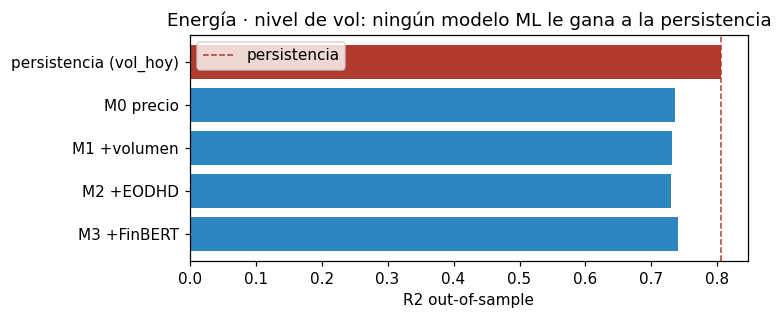

In [3]:
fig, ax = plt.subplots(figsize=(7, 3))
d = energy_level.set_index("modelo")["R2_oos"]
ax.barh(d.index, d.values, color=[RED] + [BLUE] * (len(d) - 1))
ax.axvline(d.iloc[0], color=RED, ls="--", lw=1, label="persistencia")
ax.invert_yaxis(); ax.set_xlabel("R2 out-of-sample")
ax.set_title("Energía · nivel de vol: ningún modelo ML le gana a la persistencia")
ax.legend(); plt.tight_layout()

**Lectura:** la persistencia (R² ≈ 0.81) le gana a todos los modelos ML (0.73–0.74).
La volatilidad la explica su propia autocorrelación; agregar noticias/FinBERT no mueve
la aguja. Predecir *nivel* de vol diaria con sentimiento no es viable.

## 1.2 Saltos — mejor frame, pero FinBERT sigue sin aportar

Clasificar días de shock (|ret de t+1| en el decil superior). Baseline: rankear por
`vol_t`. Acá el modelo *sí* usa las noticias — pero el aporte es del volumen, no de FinBERT.

In [4]:
from src.model.train_jumps import _clf, _label
from sklearn.metrics import roc_auc_score, average_precision_score

dj = dfe.dropna(subset=["absret_next"]).reset_index(drop=True)
dj["jump"] = _label(dj, dj["date"] < SPLIT_DATE)
tj, ej = dj[dj["date"] < SPLIT_DATE], dj[dj["date"] >= SPLIT_DATE]
bt = ej.dropna(subset=["vol_t"])

rows = [{"modelo": "base (vol_hoy)", "ROC_AUC": roc_auc_score(bt["jump"], bt["vol_t"]),
         "avg_prec": average_precision_score(bt["jump"], bt["vol_t"])}]
for name, feats in FEATURE_SETS.items():
    prob = _clf().fit(tj[feats], tj["jump"]).predict_proba(ej[feats])[:, 1]
    rows.append({"modelo": name, "ROC_AUC": roc_auc_score(ej["jump"], prob),
                 "avg_prec": average_precision_score(ej["jump"], prob)})
energy_jumps = pd.DataFrame(rows)
energy_jumps

,modelo,ROC_AUC,avg_prec
0,base (vol_hoy),0.6984,0.2530
1,M0 precio,0.6979,0.2326
2,M1 +volumen,0.7384,0.2725
3,M2 +EODHD,0.7330,0.3103
4,M3 +FinBERT,0.7524,0.2944


---
# 2. La prueba que desempata: walk-forward multi-sector

Un split único puede dar un delta positivo por azar. El **walk-forward** (6 folds
expansivos) mide si el aporte de cada bloque es consistente. Y lo corremos en 4
universos para ver si el resultado de energía generaliza.

**Sectores elegidos** (para barrer el espectro de la hipótesis sentimiento→precio):
- **tech** (NVDA, AAPL, MSFT, AMD, META, TSLA) — narrativa/hype/atención retail: *a priori el mejor caso*.
- **biotech** (MRNA, BNTX, PFE, GILD, REGN, VRTX) — eventos binarios (FDA): shocks por noticia.
- **financials** (JPM, GS, BAC, MS, WFC, C) — titulares + macro, alta cobertura: caso intermedio.
- **energía** — referencia (mercado físico). Cada ticker es su propio activo.

In [5]:
# Walk-forward unificado (macro-AUC) aplicable a cualquier panel + sets M0..M3.
from src.sectors.ablation import _clf as _clfS

CUTS = [pd.Timestamp(c, tz="UTC") for c in
        ("2023-07-01", "2024-01-01", "2024-07-01", "2025-01-01", "2025-07-01", "2026-01-01")]
HORIZON = pd.DateOffset(months=6); TOP_Q = 0.90

def macro_auc(y, score, asset):
    y, score, asset = np.asarray(y), np.asarray(score, float), np.asarray(asset)
    ok = ~np.isnan(score); aucs = []
    for a in np.unique(asset):
        m = (asset == a) & ok
        if m.sum() >= 10 and len(np.unique(y[m])) == 2:
            aucs.append(roc_auc_score(y[m], score[m]))
    return float(np.mean(aucs)) if aucs else np.nan

def jump_label(df, mask):
    thr = df[mask].groupby("asset")["absret_next"].quantile(TOP_Q)
    return (df["absret_next"] >= df["asset"].map(thr).astype(float)).astype(int)

def wf_deltas(df, sets):
    df = df.dropna(subset=["absret_next"]).reset_index(drop=True)
    blocks = {"volumen": ("M1", "M0"), "EODHD": ("M2", "M1"), "FinBERT": ("M3", "M2")}
    acc = {k: [] for k in blocks}
    for cut in CUTS:
        d = df.copy(); d["jump"] = jump_label(d, d["date"] < cut)
        a = d[d["date"] < cut]; b = d[(d["date"] >= cut) & (d["date"] < cut + HORIZON)]
        if b["jump"].sum() < 20:
            continue
        au = {n: macro_auc(b["jump"].values,
                           _clfS().fit(a[f], a["jump"]).predict_proba(b[f])[:, 1],
                           b["asset"].values) for n, f in sets.items()}
        for blk, (hi, lo) in blocks.items():
            if hi in sets and lo in sets:
                acc[blk].append(au[hi] - au[lo])
    return {k: (float(np.mean(v)) if v else np.nan) for k, v in acc.items()}
print("helpers OK")

helpers OK


In [6]:
# Panels + feature-sets uniformes (claves M0..M3) para energía y los 3 sectores.
from src.model import features as MF
from src.sectors import baskets, panel
from src.sectors.ablation import _sets as sector_sets

def energy_sets():
    b = MF.PRICE_FEATURES
    return {"M0": b, "M1": b + MF.NEWS_VOLUME,
            "M2": b + MF.NEWS_VOLUME + MF.EODHD_FEATURES,
            "M3": b + MF.NEWS_VOLUME + MF.EODHD_FEATURES + MF.FINBERT_FEATURES}

panels = {"energia": (dfe, energy_sets())}
for s in baskets.SECTORS:
    p = panel.build_panel(s)
    panels[s] = (p, sector_sets(p))
    print(f"{s:<12} filas={len(p):>5} finbert={'M3' in sector_sets(p)}")

tech         filas= 9768 finbert=True


biotech      filas= 9768 finbert=False


financials   filas= 9768 finbert=False


In [7]:
# Deltas de walk-forward por bloque, en los 4 universos.
wf = {name: wf_deltas(df, sets) for name, (df, sets) in panels.items()}
wf_tab = pd.DataFrame(wf).T[["volumen", "EODHD", "FinBERT"]]
wf_tab.columns = ["Δ volumen", "Δ EODHD", "Δ FinBERT"]
print("ΔAUC (walk-forward, macro-AUC) — aporte de cada bloque sobre el anterior:")
wf_tab

C:\Users\Juancho\AppData\Local\Temp\ipykernel_11100\676187193.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  thr = df[mask].groupby("asset")["absret_next"].quantile(TOP_Q)
C:\Users\Juancho\AppData\Local\Temp\ipykernel_11100\676187193.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  thr = df[mask].groupby("asset")["absret_next"].quantile(TOP_Q)


C:\Users\Juancho\AppData\Local\Temp\ipykernel_11100\676187193.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  thr = df[mask].groupby("asset")["absret_next"].quantile(TOP_Q)


C:\Users\Juancho\AppData\Local\Temp\ipykernel_11100\676187193.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  thr = df[mask].groupby("asset")["absret_next"].quantile(TOP_Q)


C:\Users\Juancho\AppData\Local\Temp\ipykernel_11100\676187193.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  thr = df[mask].groupby("asset")["absret_next"].quantile(TOP_Q)
C:\Users\Juancho\AppData\Local\Temp\ipykernel_11100\676187193.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  thr = df[mask].groupby("asset")["absret_next"].quantile(TOP_Q)


ΔAUC (walk-forward, macro-AUC) — aporte de cada bloque sobre el anterior:


,Δ volumen,Δ EODHD,Δ FinBERT
energia,-0.0451,0.0176,-0.0074
tech,-0.0141,-0.0025,-0.0035
biotech,0.0040,0.0034,NaN
financials,0.0315,0.0021,NaN


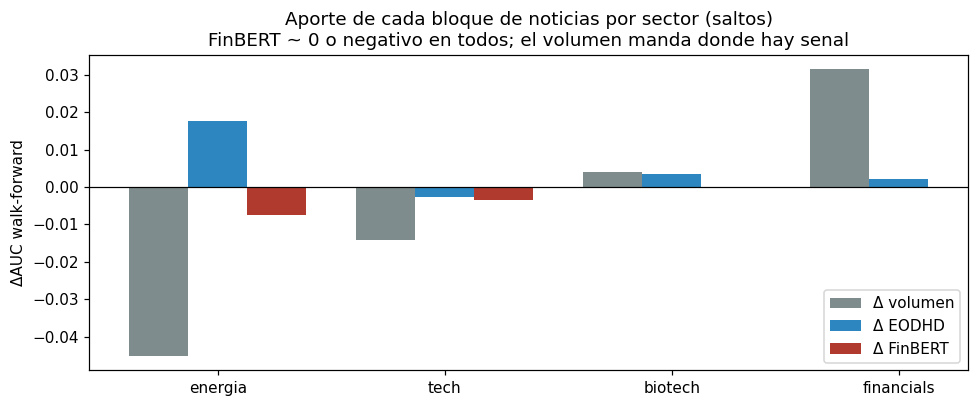

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.8))
order = [c for c in ["energia", "tech", "biotech", "financials"] if c in wf_tab.index]
sub = wf_tab.loc[order]
x = np.arange(len(order)); w = 0.26
for i, (col, color) in enumerate(zip(sub.columns, [GREY, BLUE, RED])):
    ax.bar(x + (i - 1) * w, sub[col].values, w, label=col, color=color)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(order)
ax.set_ylabel("ΔAUC walk-forward"); ax.legend()
ax.set_title("Aporte de cada bloque de noticias por sector (saltos)\n"
             "FinBERT ~ 0 o negativo en todos; el volumen manda donde hay senal")
plt.tight_layout()

**Lectura de la tabla y el gráfico:**

- **Nivel de vol (energía y sectores):** persistencia ≈ M0 ≈ M2 en todos — las noticias
  no aportan al nivel (universal).
- **FinBERT (Δ FinBERT):** ≈ 0 o **negativo** en todos los universos donde se midió
  (energía y tech). En tech —el mejor caso a priori— es −0.0035, positivo en solo 1/6 folds.
- **Volumen (Δ volumen):** es lo único con un atisbo *forward*, y aparece en **financials**
  (+0.031), no en tech (−0.014). El **tono** (EODHD/FinBERT) no aporta en ningún lado.

> *Nota:* biotech/financials tendrán su columna FinBERT cuando termine el scoring de
> títulos (job aparte, resumible). El resultado esperado, por transitividad con
> tech + energía, es el mismo. Re-ejecutar este notebook completa la tabla.

---
# 3. Por qué (la interpretación que importa para el producto)

El patrón **no es "energía es especial"**. Es más profundo:

1. **La volatilidad la domina su persistencia.** Es un hecho estilizado (vol clustering)
   universal; ninguna feature de noticias le compite al nivel.
2. **A frecuencia diaria, la noticia es contemporánea al precio, no lo anticipa.** En
   mercados líquidos la info se descuenta en segundos → mañana no queda edge. Peor cuanto
   más eficiente el mercado (mega-cap tech = hiper-eficiente).
3. **Los eventos-noticia SON el shock del mismo día** (biotech/FDA): no predicen el salto
   de mañana, coinciden con el de hoy.
4. **El único atisbo forward es el volumen de cobertura**, donde la info difunde más lento
   (financials/macro) — no donde hay más hype.

**Inversión de la hipótesis intuitiva:** tech, el candidato "obvio" para sentimiento,
es donde menos rinde.

---
# 4. Implicaciones y pivots

**Decisión sobre FinBERT:** sacarlo del producto de volatilidad. No es diferencial en
ningún sector; ahorra cómputo, latencia y complejidad. Si se usan noticias, usar
**volumen** como feature de atención/régimen (débil y sector-dependiente).

**Caveats honestos:** folds de test chicos (deltas ±0.01–0.03 rozan el ruido); se testeó
*una* familia de modelos (GBM) y *un* target (vol/saltos diarios).

**Pivots que la data aún no descarta (para explorar):**
- **Otra frecuencia** (intradía): la noticia puede *liderar* el precio por minutos.
- **Otro target** (dirección/retorno, no vol): el tono se alinea conceptualmente con el signo.
- **Volumen como régimen**: detectar estados de alta/baja atención, no regresión de nivel.
- **Event-study formal** alrededor de picos de cobertura (donde el volumen mostró su mejor cara).

*Este notebook es el entregable que cierra la evaluación de FinBERT como feature de volatilidad.*